# Active Learning of a Phase Map with Elastic K-Means

This tutorial runs a closed-loop active learning campaign in which the agent has to discover phases **from the measured curves alone**.

The virtual instrument `ParabolicPhaseMap` returns a curve for any composition $(x, y)$ in the design space $[0, 1] \times [0, 1]$. The composition space is split into three phases by two parabolas. Every curve in a phase has the same number of peaks (1, 2 or 3), but its peaks are **randomly warped along the domain**, so two curves of one phase can look quite different point by point. Plain Euclidean clustering struggles with that; elastic k-means aligns the curves before comparing them.

The synthetic phase map is a port of the example in [autophasemap](https://github.com/pozzo-research-group/autophasemap) (Vaddi, Li & Pozzo, [*Digital Discovery* 2023](https://pubs.rsc.org/en/content/articlelanding/2023/dd/d3dd00105a)).

## Set Up the Environment

`ElasticKMeansClustering` needs the optional `autophasemap` extra, which installs [ray](https://www.ray.io/) and compiles a small C extension (a C compiler is required).

In [1]:
# Uncomment to install AFL-agent with the autophasemap extra (needs a C compiler).
# !pip install "AFL-agent[autophasemap] @ git+https://github.com/usnistgov/afl-agent"

In [2]:
import logging
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import ray
import torch
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, to_rgb
from matplotlib.lines import Line2D
from sklearn.metrics import adjusted_rand_score

from AFL.double_agent.AcquisitionFunction import MaxValueAF
from AFL.double_agent.benchmarking import PhaseMapF1Score, latin_hypercube, match_labels
from AFL.double_agent.Generator import CartesianGrid
from AFL.double_agent.Pipeline import Pipeline
from AFL.double_agent.PyTorchExtrapolator import DirichletGPExtrapolator
from AFL.double_agent.representations.functionspaces import ElasticKMeansClustering
from AFL.double_agent.VirtualInstruments import ParabolicPhaseMap

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("pygsp").setLevel(logging.WARNING)  # pygsp logs every kNN graph it builds

/tmp/apm_env3/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


All settings of the campaign in one place. The number of phases is assumed known (3). Passing a list such as `[2, 3, 4]` to `n_phases` lets `ElasticKMeansClustering` choose it by BIC every iteration, at a few times the cost.

In [ ]:
SEED = 0  # instrument randomness, initial design, clustering, GP and acquisition tie-breaks
N_INITIAL = 10  # Latin hypercube measurements before the campaign
N_ITERATIONS = 30  # one new measurement per iteration
NUM_CPUS = 4  # ray workers used for the elastic alignments

# design space grid on which the GP phase map is evaluated
GRID_STEPS = 30

# phase labels from the measured curves (elastic k-means). Diffusion smoothing over the
# composition graph is off: these curves are noise-free, and the agent samples close to the
# phase boundaries, where smoothing pulls labels across the boundary.
CLUSTERING = dict(n_phases=3, n_init=3, max_iter=20, smoothen=False)

# phase classifier over composition
GP_PARAMS = {"kernel": "matern", "method": "mll", "n_iterations": 200, "verbose": False}
MODEL_DIR = tempfile.mkdtemp(prefix="afl_elastic_kmeans_gp_")  # fitted GP written here each iteration

# acquisition
DECISION_RTOL = 0.05  # pick randomly among grid points within 5% of the maximum entropy
# MaxValueAF passes exclusion_radius to GaussianPoints as the *variance* of a Gaussian placed on
# every measured composition: 1e-3 means a standard deviation of ~0.03, about one grid step here
EXCLUSION_RADIUS = 1e-3

# benchmark
N_TEST_PER_PHASE = 100  # stratified test points per phase for the F1 score

## Plotting Helpers

In [4]:
PHASE_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
PHASE_NAMES = {1: "Phase 1 (1 peak)", 2: "Phase 2 (2 peaks)", 3: "Phase 3 (3 peaks)"}
UNMATCHED = "#c3c2b7"
SURFACE, INK, INK_SECONDARY, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRIDLINE, BASELINE = "#e1e0d9", "#c3c2b7"
ENTROPY_CMAP = LinearSegmentedColormap.from_list(
    "entropy_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
    "legend.frameon": False, "legend.labelcolor": INK_SECONDARY,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round",
    "savefig.dpi": 200, "figure.dpi": 100,
})


def tint(color, amount=0.72):
    # lighter tint of ``color`` (mixed toward the surface) for filled phase regions
    rgb, surface = np.array(to_rgb(color)), np.array(to_rgb(SURFACE))
    return tuple(rgb + (surface - rgb) * amount)


REGION_LEVELS = [-1, 1, 2, 3]  # -1: GP class that matches no true phase
REGION_CMAP = ListedColormap([tint(UNMATCHED, 0.4)] + [tint(PHASE_COLORS[p]) for p in (1, 2, 3)])


def grid_image(grid, values):
    # regular-grid image (xs, ys, Z) from grid points (n, 2) and values (n,)
    xs, ys = np.unique(grid[:, 0]), np.unique(grid[:, 1])
    Z = np.full((ys.size, xs.size), np.nan)
    Z[np.searchsorted(ys, grid[:, 1]), np.searchsorted(xs, grid[:, 0])] = values
    return xs, ys, Z


def draw_phase_regions(ax, grid, labels):
    xs, ys, Z = grid_image(grid, np.searchsorted(REGION_LEVELS, labels))
    ax.pcolormesh(xs, ys, Z, cmap=REGION_CMAP, vmin=-0.5, vmax=3.5, shading="nearest", rasterized=True)


def draw_true_boundaries(ax):
    x = np.linspace(0, 1, 200)
    for boundary in (ParabolicPhaseMap.upper_boundary, ParabolicPhaseMap.lower_boundary):
        ax.plot(x, boundary(x), color=INK_SECONDARY, linewidth=1.0)


def setup_composition_axes(ax, title=None):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.spines[["top", "right"]].set_visible(True)
    if title:
        ax.set_title(title, loc="left")


def draw_points(ax, comps, color=INK, size=8, marker="o", **kwargs):
    # markers with a surface-colored ring so overlapping points stay readable
    return ax.plot(comps[:, 0], comps[:, 1], linestyle="none", marker=marker, markersize=size,
                   markerfacecolor=color, markeredgecolor=SURFACE, markeredgewidth=1.5, **kwargs)


def phase_legend_handles(include_unmatched=False):
    phases = [(PHASE_NAMES[p], tint(PHASE_COLORS[p]), PHASE_COLORS[p]) for p in (1, 2, 3)]
    if include_unmatched:
        phases.append(("Unmatched cluster", tint(UNMATCHED, 0.4), UNMATCHED))
    return [Line2D([], [], linestyle="none", marker="s", markersize=10, markerfacecolor=face,
                   markeredgecolor=edge, label=name) for name, face, edge in phases]

## The Virtual Instrument

The design space is the unit square $[0, 1] \times [0, 1]$ and any composition in it can be measured. `ParabolicPhaseMap.measure` takes one or more $(x, y)$ compositions and returns a dataset with the `composition`, the measured curve `measurement` over the domain `t`, and the `ground_truth_labels`. The agent only ever uses `composition` and `measurement`; the labels are kept for benchmarking.

In [5]:
sim = ParabolicPhaseMap(overrides={"random_seed": SEED}, afl_home=tempfile.mkdtemp(prefix="afl_home_"))
COMPONENTS = sim.components
LIMITS = dict(ParabolicPhaseMap.DESIGN_SPACE)  # the design space: [0, 1] x [0, 1]
print(COMPONENTS, LIMITS)
sim.measure([[0.5, 0.9], [0.5, 0.1], [0.5, 0.5]])

['x', 'y'] {'x': (0.0, 1.0), 'y': (0.0, 1.0)}


<xarray.Dataset> Size: 3kB
Dimensions:              (sample: 3, component: 2, t: 100)
Coordinates:
  * sample               (sample) int64 24B 0 1 2
  * component            (component) <U1 8B 'x' 'y'
  * t                    (t) float64 800B 0.0 0.0101 0.0202 ... 0.9899 1.0
Data variables:
    composition          (sample, component) float64 48B 0.5 0.9 0.5 0.1 0.5 0.5
    measurement          (sample, t) float64 2kB 0.3204 0.3299 ... 0.4219 0.3018
    ground_truth_labels  (sample) int64 24B 1 2 3

The campaign starts from a small Latin hypercube design. Its curves show what the agent has to work with: within each phase the number of peaks is fixed, but their positions move from curve to curve.

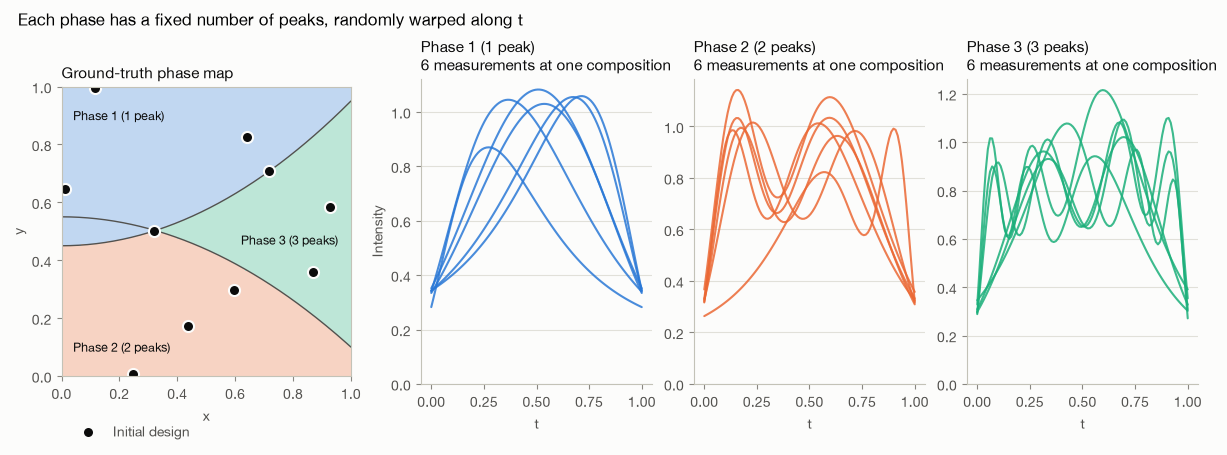

In [6]:
np.random.seed(SEED)
torch.manual_seed(SEED)
initial_design = latin_hypercube(LIMITS, N_INITIAL, seed=SEED)
ds_initial = sim.measure(initial_design)

# ground truth on a fine grid (for plots only)
axes_1d = [np.linspace(*LIMITS[c], 200) for c in COMPONENTS]
truth_grid = np.stack(np.meshgrid(*axes_1d, indexing="ij"), axis=-1).reshape(-1, len(COMPONENTS))
truth_labels = sim.phase_labels(truth_grid)

# a few extra curves per phase, from a separate instrument so the campaign's random stream is untouched
examples = ParabolicPhaseMap(overrides={"random_seed": SEED + 1}, afl_home=tempfile.mkdtemp())
example_points = {1: [0.5, 0.95], 2: [0.5, 0.05], 3: [0.5, 0.5]}
example_curves = {p: examples.measure(np.repeat([xy], 6, axis=0)) for p, xy in example_points.items()}

fig = plt.figure(figsize=(12, 4.4), layout="constrained")
gs = fig.add_gridspec(1, 4, width_ratios=[1.25, 1, 1, 1])
ax = fig.add_subplot(gs[0])
draw_phase_regions(ax, truth_grid, truth_labels)
draw_true_boundaries(ax)
for phase, (x, y) in {1: (0.04, 0.9), 2: (0.04, 0.1), 3: (0.62, 0.47)}.items():
    ax.text(x, y, PHASE_NAMES[phase], color=INK, fontsize=9, va="center")
draw_points(ax, initial_design, label="Initial design")
setup_composition_axes(ax, "Ground-truth phase map")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, -0.12))
for i, phase in enumerate((1, 2, 3)):
    axc = fig.add_subplot(gs[i + 1], sharey=None)
    curves = example_curves[phase]
    for curve in curves["measurement"].values:
        axc.plot(curves["t"], curve, color=PHASE_COLORS[phase], linewidth=1.5, alpha=0.85)
    axc.set_title(f"{PHASE_NAMES[phase]}\n6 measurements at one composition", loc="left")
    axc.set_xlabel("t")
    axc.set_ylim(bottom=0)
    axc.grid(axis="y", color=GRIDLINE, linewidth=0.8)
    axc.set_axisbelow(True)
    if i == 0:
        axc.set_ylabel("Intensity")
fig.suptitle("Each phase has a fixed number of peaks, randomly warped along t", x=0.01, ha="left", fontsize=12)
plt.show()

## Build the Pipeline

In [7]:
with Pipeline(name="elastic_kmeans_active_learning") as pipeline:
    CartesianGrid(
        output_variable="design_space_grid",
        sample_dim="grid",
        component_dim="component",
        grid_spec={c: {"min": LIMITS[c][0], "max": LIMITS[c][1], "steps": GRID_STEPS} for c in COMPONENTS},
        name="Grid-DesignSpace",
    )
    ElasticKMeansClustering(
        functions_variable="measurement",
        components_variable="composition",
        domain_dim="t",
        output_prefix="clusters",
        store_alignment=True,
        seed=SEED,
        **CLUSTERING,
    )
    DirichletGPExtrapolator(
        feature_input_variable="composition",
        predictor_input_variable="clusters_labels",
        output_prefix="phase",
        grid_variable="design_space_grid",
        grid_dim="grid",
        sample_dim="sample",
        component_dim="component",
        params=GP_PARAMS,
        standardize=True,
        bounds=LIMITS,
        model_uri=MODEL_DIR,
        name="DirichletGP-PhaseMap",
    )
    PhaseMapF1Score(
        ground_truth=sim,
        model_variable="phase_model",
        average="weighted",
        n_per_phase=N_TEST_PER_PHASE,
        seed=SEED,
        match_labels=True,
        output_prefix="benchmark",
        name="PhaseMapF1Score",
    )
    MaxValueAF(
        input_variables=["phase_entropy"],
        grid_variable="design_space_grid",
        grid_dim="grid",
        output_variable="next_composition",
        decision_rtol=DECISION_RTOL,
        excluded_comps_variables=["composition"],
        excluded_comps_dim="component",
        exclusion_radius=EXCLUSION_RADIUS,
        count=1,
        sample_dim="next_sample",
        name="MaxValueAF-Entropy",
    )

for i, op in enumerate(pipeline):
    print(i, op.name)

0 Grid-DesignSpace
1 ElasticKMeansClustering
2 DirichletGP-PhaseMap
3 PhaseMapF1Score
4 MaxValueAF-Entropy


## Run the Active Learning Campaign

`ray` runs the elastic alignments in parallel; it is started once here and reused by every iteration.

In [ ]:
ray.init(num_cpus=NUM_CPUS, 
         include_dashboard=False, 
         log_to_driver=False, 
         ignore_reinit_error=True,
         logging_level=logging.ERROR
    )

measured = ds_initial.copy()
acquired_at = [0] * N_INITIAL  # iteration after which each sample was measured (0 = initial design)
history = {k: [] for k in ["n_measurements", "f1", "accuracy", "cluster_ari", "seconds"]}
phase_maps, entropies, next_points = [], [], []

campaign_start = time.time()
for iteration in range(N_ITERATIONS + 1):
    start = time.time()
    result = pipeline.calculate(measured, disable_progress_bar=True)
    seconds = time.time() - start

    truth = measured["ground_truth_labels"].values
    clusters = result["clusters_labels"].values
    _, mapping = match_labels(truth, clusters)  # plotting only
    next_point = result["next_composition"].transpose("next_sample", "component").values

    history["n_measurements"].append(measured.sizes["sample"])
    history["f1"].append(result["benchmark_f1"].item())
    history["accuracy"].append(result["benchmark_accuracy"].item())
    history["cluster_ari"].append(adjusted_rand_score(truth, clusters))
    history["seconds"].append(seconds)
    phase_maps.append(np.array([mapping.get(int(c), -1) for c in result["phase_mean"].values]))
    entropies.append(result["phase_entropy"].values)
    next_points.append(next_point[0])

    print(f"[{iteration:2d}/{N_ITERATIONS}] n={history['n_measurements'][-1]:2d} "
          f"F1={history['f1'][-1]:.3f} accuracy={history['accuracy'][-1]:.3f} "
          f"cluster ARI={history['cluster_ari'][-1]:.3f} "
          f"next=({next_point[0, 0]:.2f}, {next_point[0, 1]:.2f})  [{seconds:.1f} s]")

    if iteration < N_ITERATIONS:  # the last run only scores the final data set
        new = sim.measure(next_point).assign_coords(sample=[measured.sizes["sample"]])
        measured = xr.concat([measured, new], dim="sample")
        acquired_at.append(iteration + 1)

print(f"\ncampaign took {time.time() - campaign_start:.0f} s")

[ 0/30] n=10 F1=0.722 accuracy=0.733 cluster ARI=1.000 next=(0.72, 0.52)  [7.9 s]


[ 1/30] n=11 F1=0.713 accuracy=0.720 cluster ARI=1.000 next=(0.00, 0.45)  [3.3 s]


[ 2/30] n=12 F1=0.739 accuracy=0.747 cluster ARI=1.000 next=(0.62, 0.55)  [3.8 s]


[ 3/30] n=13 F1=0.758 accuracy=0.763 cluster ARI=1.000 next=(0.48, 0.59)  [2.7 s]


[ 4/30] n=14 F1=0.770 accuracy=0.777 cluster ARI=1.000 next=(0.55, 0.52)  [6.6 s]


[ 5/30] n=15 F1=0.781 accuracy=0.787 cluster ARI=1.000 next=(0.41, 0.55)  [8.4 s]


... (21 outputs left out)

[27/30] n=37 F1=0.909 accuracy=0.910 cluster ARI=1.000 next=(0.90, 0.07)  [15.4 s]


[28/30] n=38 F1=0.926 accuracy=0.927 cluster ARI=1.000 next=(0.69, 0.62)  [12.2 s]


[29/30] n=39 F1=0.936 accuracy=0.937 cluster ARI=1.000 next=(0.00, 0.00)  [8.5 s]


[30/30] n=40 F1=0.943 accuracy=0.943 cluster ARI=1.000 next=(0.48, 0.41)  [6.9 s]

campaign took 268 s


In [9]:
results = xr.Dataset(
    {
        "composition": measured["composition"],
        "measurement": measured["measurement"],
        "ground_truth_labels": measured["ground_truth_labels"],
        "acquired_at": ("sample", np.asarray(acquired_at)),
        "cluster_labels": ("sample", result["clusters_labels"].values),
        "cluster_templates": result["clusters_templates"].rename(clusters_phase="cluster"),
        "cluster_aligned": result["clusters_aligned"].rename(clusters_phase="cluster"),
        "design_space_grid": result["design_space_grid"].transpose("grid", "component"),
        "n_measurements": ("iteration", history["n_measurements"]),
        "f1": ("iteration", history["f1"]),
        "accuracy": ("iteration", history["accuracy"]),
        "cluster_ari": ("iteration", history["cluster_ari"]),
        "seconds": ("iteration", history["seconds"]),
        "phase_map": (("iteration", "grid"), np.stack(phase_maps)),
        "entropy": (("iteration", "grid"), np.stack(entropies)),
        "next_composition": (("iteration", "component"), np.stack(next_points)),
    },
    coords={"iteration": np.arange(N_ITERATIONS + 1)},
)
results["ground_truth_grid"] = ("grid", sim.phase_labels(results["design_space_grid"].values))
results

<xarray.Dataset> Size: 603kB
Dimensions:              (sample: 40, component: 2, t: 100, cluster: 3,
                          grid: 900, iteration: 31)
Coordinates:
  * sample               (sample) int64 320B 0 1 2 3 4 5 6 ... 34 35 36 37 38 39
  * component            (component) <U1 8B 'x' 'y'
  * t                    (t) float64 800B 0.0 0.0101 0.0202 ... 0.9899 1.0
  * cluster              (cluster) int64 24B 0 1 2
  * iteration            (iteration) int64 248B 0 1 2 3 4 5 ... 26 27 28 29 30
Dimensions without coordinates: grid
Data variables: (12/17)
    composition          (sample, component) float64 640B 0.4363 0.173 ... 0.0
    measurement          (sample, t) float64 32kB 0.3045 0.3103 ... 0.3676
    ground_truth_labels  (sample) int64 320B 2 2 1 1 2 2 1 3 ... 3 1 3 1 3 2 3 2
    acquired_at          (sample) int64 320B 0 0 0 0 0 0 0 ... 25 26 27 28 29 30
    cluster_labels       (sample) int64 320B 1 1 2 2 1 1 2 0 ... 0 2 0 2 0 1 0 1
    cluster_templates    (cluster, t) float64 2kB 0.4028 0.4286 ... 0.4475
    ...                   ...
    cluster_ari          (iteration) float64 248B 1.0 1.0 1.0 ... 1.0 1.0 1.0
    seconds              (iteration) float64 248B 7.88 3.306 ... 8.549 6.869
    phase_map            (iteration, grid) int64 223kB 2 2 2 2 2 2 ... 3 1 1 1 1
    entropy              (iteration, grid) float64 223kB 0.7394 ... 0.6268
    next_composition     (iteration, component) float64 496B 0.7241 ... 0.4138
    ground_truth_grid    (grid) int64 7kB 2 2 2 2 2 2 2 2 2 ... 3 3 3 3 3 3 1 1

## Visualize the Campaign

### How the phase map develops

Snapshots of the predicted phase map (regions), the measurements so far (black points) and the next measurement (open circle). The thin gray lines are the true boundaries. Gray regions are GP classes that do not match any true phase.

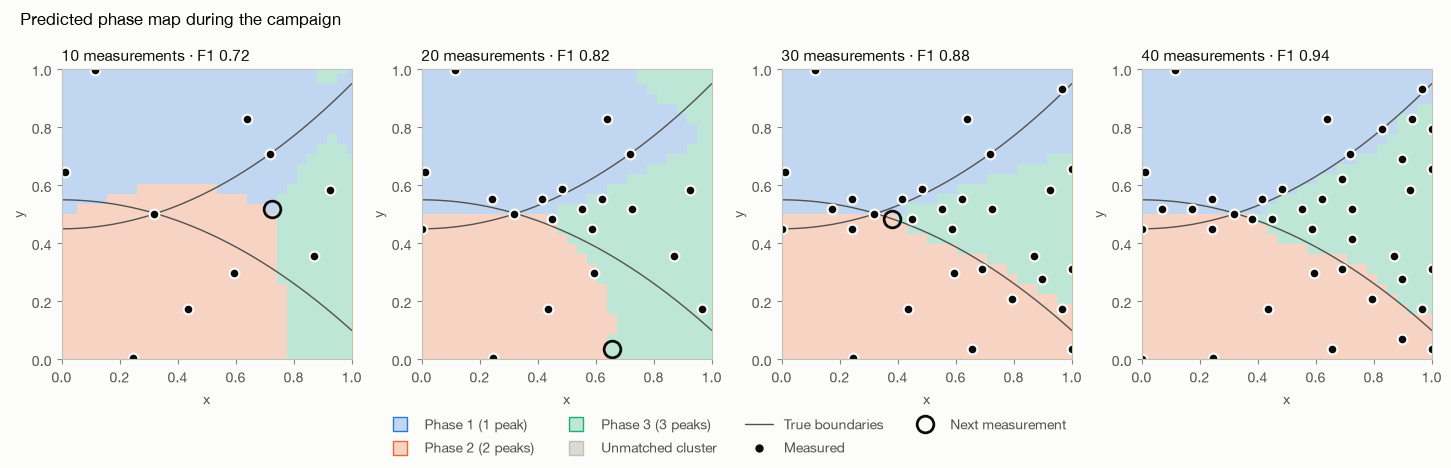

In [10]:
grid = results["design_space_grid"].values
comps = results["composition"].values
acquired = results["acquired_at"].values
snapshots = sorted({0, N_ITERATIONS // 3, 2 * N_ITERATIONS // 3, N_ITERATIONS})

fig, axes = plt.subplots(1, len(snapshots), figsize=(3.6 * len(snapshots), 4.6), layout="constrained")
for ax, it in zip(axes, snapshots):
    draw_phase_regions(ax, grid, results["phase_map"].sel(iteration=it).values)
    draw_true_boundaries(ax)
    draw_points(ax, comps[acquired <= it], size=7)
    if it < N_ITERATIONS:
        nxt = results["next_composition"].sel(iteration=it).values
        ax.plot(*nxt, linestyle="none", marker="o", markersize=12, markerfacecolor="none",
                markeredgecolor=INK, markeredgewidth=2.0)
    n = int(results["n_measurements"].sel(iteration=it))
    setup_composition_axes(ax, f"{n} measurements · F1 {float(results['f1'].sel(iteration=it)):.2f}")
handles = phase_legend_handles(include_unmatched=True) + [
    Line2D([], [], color=INK_SECONDARY, linewidth=1.0, label="True boundaries"),
    Line2D([], [], linestyle="none", marker="o", markersize=7, markerfacecolor=INK,
           markeredgecolor=SURFACE, label="Measured"),
    Line2D([], [], linestyle="none", marker="o", markersize=12, markerfacecolor="none",
           markeredgecolor=INK, markeredgewidth=2.0, label="Next measurement"),
]
fig.legend(handles=handles, loc="outside lower center", ncol=4)
fig.suptitle("Predicted phase map during the campaign", x=0.01, ha="left", fontsize=12)
plt.show()

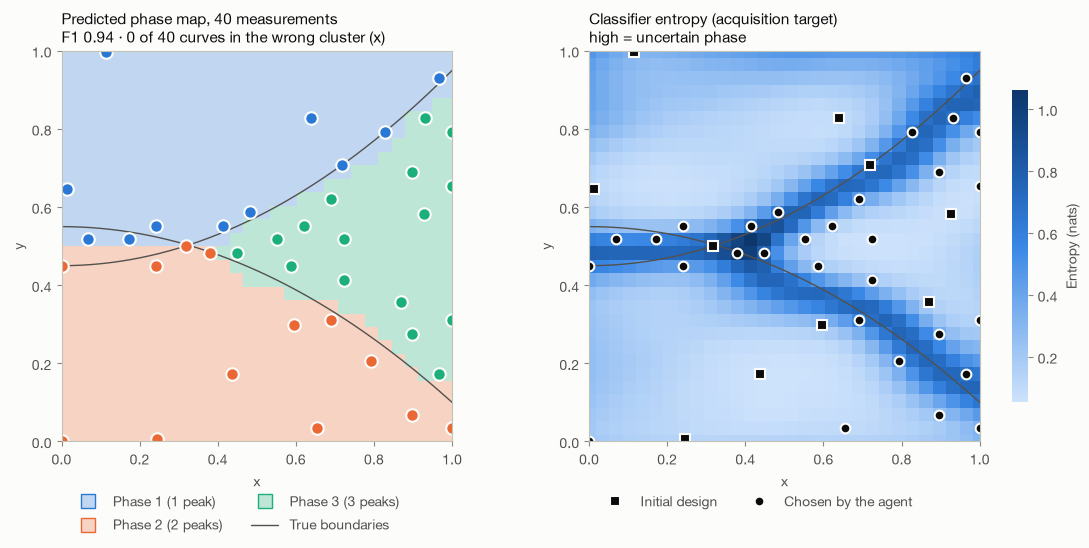

In [11]:
matched, _ = match_labels(results["ground_truth_labels"].values, results["cluster_labels"].values)
wrong = matched != results["ground_truth_labels"].values
n_final = int(results["n_measurements"][-1])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.4), layout="constrained")
draw_phase_regions(ax1, grid, results["phase_map"].isel(iteration=-1).values)
draw_true_boundaries(ax1)
for phase in (1, 2, 3):
    draw_points(ax1, comps[matched == phase], color=PHASE_COLORS[phase], size=9)
if wrong.any():
    ax1.plot(comps[wrong, 0], comps[wrong, 1], linestyle="none", marker="x", markersize=7,
             color=INK, markeredgewidth=1.5)
setup_composition_axes(ax1, f"Predicted phase map, {n_final} measurements\n"
                            f"F1 {float(results['f1'][-1]):.2f} · {int(wrong.sum())} of {n_final} "
                            "curves in the wrong cluster (x)")
ax1.legend(handles=phase_legend_handles() + [Line2D([], [], color=INK_SECONDARY, linewidth=1.0,
                                                    label="True boundaries")],
           loc="upper left", bbox_to_anchor=(0.0, -0.1), ncol=2)

xs, ys, Z = grid_image(grid, results["entropy"].isel(iteration=-1).values)
mesh = ax2.pcolormesh(xs, ys, Z, cmap=ENTROPY_CMAP, shading="nearest", rasterized=True)
draw_true_boundaries(ax2)
initial = acquired == 0
draw_points(ax2, comps[initial], marker="s", size=7, label="Initial design")
draw_points(ax2, comps[~initial], size=7, label="Chosen by the agent")
setup_composition_axes(ax2, "Classifier entropy (acquisition target)\nhigh = uncertain phase")
cbar = fig.colorbar(mesh, ax=ax2, shrink=0.8)
cbar.set_label("Entropy (nats)", color=INK_SECONDARY)
cbar.outline.set_visible(False)
ax2.legend(loc="upper left", bbox_to_anchor=(0.0, -0.1), ncol=2)
plt.show()

### What elastic k-means learned

The final clusters: every member curve after alignment to its cluster template (gray) and the template itself (phase color). Alignment removes the random warping, so the templates show the clean 1-, 2- and 3-peak shapes.

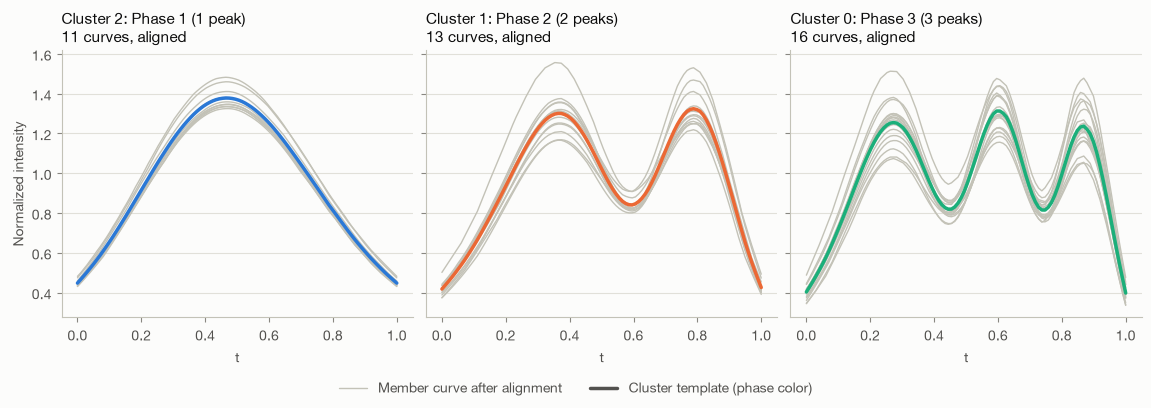

In [13]:
labels = results["cluster_labels"].values
_, mapping = match_labels(results["ground_truth_labels"].values, labels)
t = results["t"].values
clusters = sorted(np.unique(labels), key=lambda c: mapping.get(int(c), 99))

fig, axes = plt.subplots(1, len(clusters), figsize=(3.8 * len(clusters), 4.0), layout="constrained",
                         sharey=True)
for ax, cluster in zip(axes, clusters):
    phase = mapping.get(int(cluster))
    members = np.flatnonzero(labels == cluster)
    for j in members:
        ax.plot(t, results["cluster_aligned"].values[j, cluster], color=BASELINE, linewidth=1.0)
    ax.plot(t, results["cluster_templates"].values[cluster], color=PHASE_COLORS.get(phase, UNMATCHED),
            linewidth=2.5)
    ax.set_title(f"Cluster {cluster}: {PHASE_NAMES.get(phase, 'unmatched')}\n{members.size} curves, aligned",
                 loc="left")
    ax.set_xlabel("t")
    ax.grid(axis="y", color=GRIDLINE, linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Normalized intensity")
fig.legend(handles=[Line2D([], [], color=BASELINE, linewidth=1.0, label="Member curve after alignment"),
                    Line2D([], [], color=INK_SECONDARY, linewidth=2.5, label="Cluster template (phase color)")],
           loc="outside lower center", ncol=2)
plt.show()

In [14]:
ray.shutdown()

## Summary

- The agent learned the phase map from curves alone: `ElasticKMeansClustering` turned measurements into phase labels, `DirichletGPExtrapolator` interpolated them over composition, and `MaxValueAF` on the classifier entropy placed new measurements along the uncertain phase boundaries.
- Elastic alignment is what makes the labels usable here: curves of one phase differ by a random warping of the domain, which the clustering factors out.
- `PhaseMapF1Score(match_labels=True)` benchmarks a classifier trained on unsupervised labels by first matching cluster indices to the true phases.

Things to try:

- `CLUSTERING["n_phases"] = [2, 3, 4]` to let the clustering choose the number of phases by BIC.
- A noisier instrument: `ParabolicPhaseMap(overrides={"noise": 0.05, ...})`.
- A larger `max_warp` in the instrument overrides to make the phases harder to separate.